# SVM - CS231

## Mount tới drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Import các thư viện cần thiết

In [ ]:
import os
import cv2
import numpy as np
import joblib
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

## Hàm trích xuất đặc trưng và hàm đọc data từ thư mục

In [ ]:
def features_extraction(img_path, config='hog-only', img_size=(128, 128)):
    img = cv2.imread(img_path)
    if img is None:
        return None

    img = cv2.resize(img, img_size)
    features = []

    if 'hog' in config:
        gray_scale = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        hog_features = hog(
            gray_scale,
            orientations=8,
            pixels_per_cell=(16, 16),
            cells_per_block=(2, 2),
            feature_vector=True
        )

        features.extend(hog_features)

    if 'color' in config:
        hsv_scale = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

        hist = cv2.calcHist([hsv_scale], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256])
        cv2.normalize(hist, hist)
        features.extend(hist.flatten())

    return np.array(features)

def load_data(data_dir, config='hog-only', img_size=(128, 128)):
    images = []
    labels = []
    class_names = sorted(os.listdir(data_dir))

    for label, class_name in enumerate(class_names):
        class_folder = os.path.join(data_dir, class_name)
        if os.path.isdir(class_folder):
            for img_name in os.listdir(class_folder):
                img_path = os.path.join(class_folder, img_name)
                features = features_extraction(img_path, config, img_size)

                if features is not None:
                    images.append(features)
                    labels.append(label)
    return np.array(images), np.array(labels), class_names

## Thử nghiệm 1: Chỉ sử dụng HOG

### Đọc dữ liệu

In [ ]:
base_dir = '/content/drive/MyDrive/CS231.Q21/dataset/fruit'

CONFIG_1 = 'hog-only'
CONFIG_2 = 'hog-color'

X_train, y_train, classes = load_data(os.path.join(base_dir, 'train'), config=CONFIG_1)
X_val, y_val, _ = load_data(os.path.join(base_dir, 'val'), config=CONFIG_1)
X_test, y_test, _ = load_data(os.path.join(base_dir, 'test'), config=CONFIG_1)

print(f"X_train shape: {X_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"X_test shape: {X_test.shape}")

# Chuẩn hóa dữ liệu (StandardScaler)
scaler_1 = StandardScaler()
X_train_scaled = scaler_1.fit_transform(X_train)
X_val_scaled = scaler_1.transform(X_val)
X_test_scaled = scaler_1.transform(X_test)
print('Đã chuẩn hóa dữ liệu bằng StandardScaler')

X_train shape: (4200, 1568)
X_val shape: (900, 1568)
X_test shape: (900, 1568)
Đã chuẩn hóa dữ liệu bằng StandardScaler


### Tuning tham só C và gamma

In [ ]:
# GridSearchCV để tìm tham số tối ưu
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.1, 0.01],
    'kernel': ['rbf']
}

grid_search_1 = GridSearchCV(
    estimator=SVC(),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid_search_1.fit(X_train_scaled, y_train)

best_hog_only = grid_search_1.best_estimator_
print(f"\nBest Params: {grid_search_1.best_params_}")
print(f"Best CV Accuracy (5-fold): {grid_search_1.best_score_:.4f}")

# Đánh giá trên tập validation
val_acc = accuracy_score(y_val, best_hog_only.predict(X_val_scaled))
print(f"Validation Accuracy: {val_acc:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits

Best Params: {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV Accuracy (5-fold): 0.7055
Validation Accuracy: 0.6067


### Sử dụng mô hình tốt nhất và kiểm tra kết quả

              precision    recall  f1-score   support

       apple       0.61      0.54      0.57       180
      banana       0.66      0.70      0.68       180
       mango       0.54      0.58      0.56       180
      orange       0.55      0.51      0.53       180
      tomato       0.62      0.64      0.63       180

    accuracy                           0.60       900
   macro avg       0.60      0.60      0.59       900
weighted avg       0.60      0.60      0.59       900



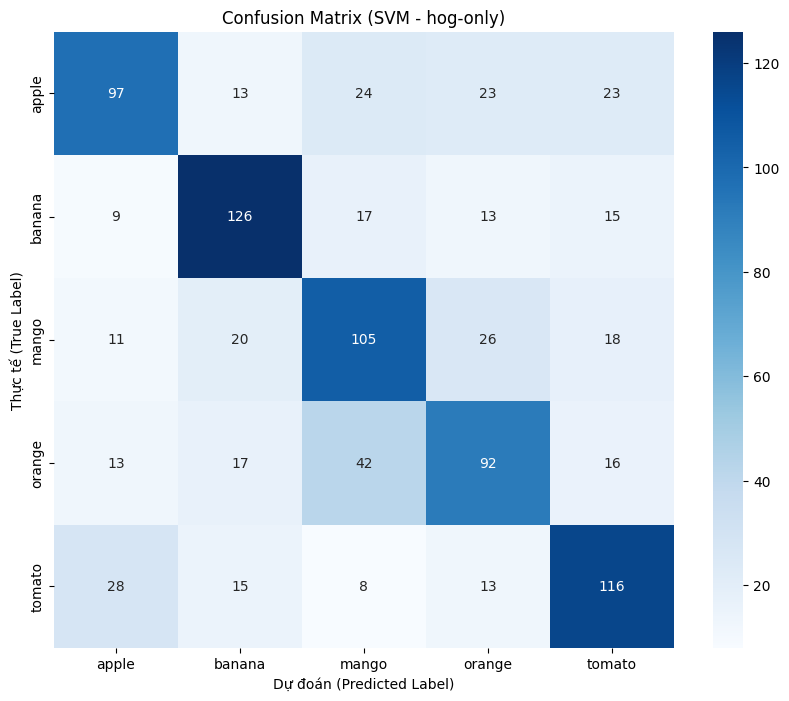

In [ ]:
y_pred = best_hog_only.predict(X_test_scaled)

print(classification_report(y_test, y_pred, target_names=classes))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title(f'Confusion Matrix (SVM - {CONFIG_1})')
plt.ylabel('Thực tế (True Label)')
plt.xlabel('Dự đoán (Predicted Label)')
plt.show()

## Thử nghiệm 2: Sử dụng HOG và Color Histogram

### Đọc dữ liệu

In [ ]:
X_train, y_train, classes = load_data(os.path.join(base_dir, 'train'), config=CONFIG_2)
X_val, y_val, _ = load_data(os.path.join(base_dir, 'val'), config=CONFIG_2)
X_test, y_test, _ = load_data(os.path.join(base_dir, 'test'), config=CONFIG_2)

print(f"X_train shape: {X_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"X_test shape: {X_test.shape}")

# Chuẩn hóa dữ liệu (StandardScaler)
scaler_2 = StandardScaler()
X_train_scaled = scaler_2.fit_transform(X_train)
X_val_scaled = scaler_2.transform(X_val)
X_test_scaled = scaler_2.transform(X_test)
print('Đã chuẩn hóa dữ liệu bằng StandardScaler')

X_train shape: (4200, 2080)
X_val shape: (900, 2080)
X_test shape: (900, 2080)
Đã chuẩn hóa dữ liệu bằng StandardScaler


### Tuning tham số C và gamma

In [ ]:
# GridSearchCV để tìm tham số tối ưu
grid_search_2 = GridSearchCV(
    estimator=SVC(),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid_search_2.fit(X_train_scaled, y_train)

best_hog_color = grid_search_2.best_estimator_
print(f"\nBest Params: {grid_search_2.best_params_}")
print(f"Best CV Accuracy (5-fold): {grid_search_2.best_score_:.4f}")

# Đánh giá trên tập validation
val_acc = accuracy_score(y_val, best_hog_color.predict(X_val_scaled))
print(f"Validation Accuracy: {val_acc:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits

Best Params: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV Accuracy (5-fold): 0.8495
Validation Accuracy: 0.8256


### Sử dụng mô hình tốt nhất và kiểm tra kết quả

              precision    recall  f1-score   support

       apple       0.91      0.75      0.82       180
      banana       0.80      0.91      0.85       180
       mango       0.83      0.84      0.84       180
      orange       0.84      0.84      0.84       180
      tomato       0.81      0.81      0.81       180

    accuracy                           0.83       900
   macro avg       0.83      0.83      0.83       900
weighted avg       0.83      0.83      0.83       900



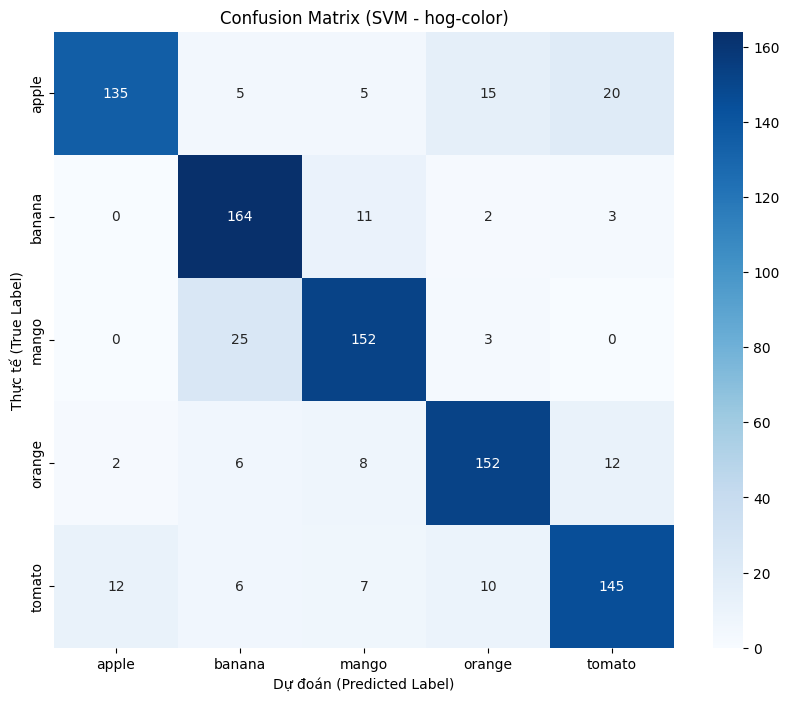

In [ ]:
y_pred = best_hog_color.predict(X_test_scaled)

print(classification_report(y_test, y_pred, target_names=classes))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title(f'Confusion Matrix (SVM - {CONFIG_2})')
plt.ylabel('Thực tế (True Label)')
plt.xlabel('Dự đoán (Predicted Label)')
plt.show()

In [ ]:
import joblib

# Define the path to save the model
model_save_path = '/content/drive/MyDrive/CS231.Q21/models/svm_hog_color_model.joblib'

# Save the best trained model (best_hog_color) to the specified path
joblib.dump(best_hog_color, model_save_path)

print(f"Mô hình đã được lưu tại: {model_save_path}")

Mô hình đã được lưu tại: /content/drive/MyDrive/CS231.Q21/models/svm_hog_color_model.joblib


Để tải lại mô hình, bạn có thể sử dụng đoạn code sau:

In [ ]:
# Load the model back
loaded_model = joblib.load(model_save_path)
print("Mô hình đã được tải lại thành công!")

Mô hình đã được tải lại thành công!
